
# Lab 11: Clustering
### COMM 4259 <br> <i>Foundations of Machine Learning and AI</i>
© Jingjing Li- Ask for permission for using/quoting: jingjing.li@virginia.edu



## Lab Prep
* If you would like to see my screen on your computer, you can use a web browser to log in to Zoom, turn off the speaker and mute yourself.
    - Section 001, 11:00 a.m. – 12:15 p.m.: https://mcintire.zoom.us/j/95993311893?pwd=NmabjMgwCFyKkxzib3qMFahEDkkaSI.1
    - Section 002, 2:00 – 3:15 p.m.: https://mcintire.zoom.us/j/97629389481?pwd=GA37uPdbfC0154k4M3n17SGf6qaYCg.1
* Have VS Code open with your `comm4259-work` folder before we start.

## Lab Rules
* Raise hands for questions
* Be prepared to share your screen for Q & A or exercises

# Before You Start: Save the Lab Files to GitHub
1. Download `lab_11.zip` from Canvas, move it into your `comm4259-work` folder, and unzip it there. You now have `comm4259-work/lab_11/` with this notebook and its data.
2. In VS Code, open `comm4259-work` and a terminal (Terminal > New Terminal). From `comm4259-work`, commit and push the files you just downloaded:

```
git add .
git commit -m "Lab 11: downloaded the lab files"
git push
```

Your repository now has the starting copy, and your commit at the end of class shows the work you did in the lab.

# Learning Objectives
In this lab we will conduct a market segment analysis for an online retailer. Specifically, we will learn:
- Conduct K-Means clustering
- Evaluate clustering and select the K
- Create centroid table
- Interpret the clusters and build personas
- Claude Code: get a second opinion from an independent agent, and decide with the numbers. (optional, after class)


# Clustering Overview
## What is Clustering Analysis?
Finding groups of objects such that the objects in a group will be similar (or related) to one another and different from (or unrelated to) the objects in other groups.

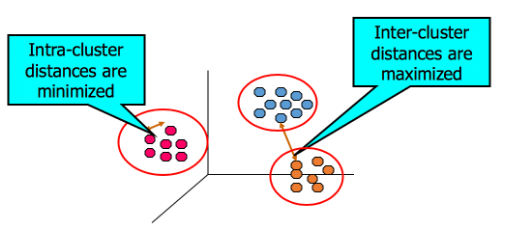

<div style="background-color:#FFF4CE; color:#5C4200; border:1px solid #E8C86E; border-left:5px solid #D69E00; padding:15px; border-radius:4px;">
<b>Note: What is the difference between Classification and Clustering?</b><br> 
    Classification and Clustering processes appear to be similar, but there is a difference between them in the context of data mining. The main difference is that <b>classification is used in supervised learning</b>, where predefined labels are assigned to instances based on their properties, whereas <b>clustering is used in unsupervised learning</b>, where similar instances are grouped based on their features or properties.
    
</div>

## Types of Clustering
- Partitional Clustering (K-Means)
    - A division of data objects into non-overlapping subsets (clusters) such that each data object is in exactly one subset



# Clustering for Best Buy Customers
We discussed the Best Buy case (Jill, Ray, Buzz and Barry) in the lecture slides. In this lab, you apply the same idea, clustering customers and building personas, to an online retailer.


# Partitional Clustering: K-Means

## Choose K
- Option 1: If we have prior knowledge about the dataset. e.g., I know that my data will have two clusters (Usually, it’s a rare situation)

- Option 2: We don’t have any knowledge about the dataset, we just try a range of K’s. 
For each solution, we calculate the inter cluster distance and intra cluster distance, and pick the best solution with the highest inter and lowest intra cluster distance. 




## Evaluating K-means Clusters
- Most common measure is Sum of Squared Error (SSE)
    - Measure intra cluster distance
    - For each point, the error is the distance to the nearest cluster centroid
    - To get SSE, we square these errors and sum them.
    - $x$ is a data point in cluster $C_i$ and $m_i$ is the representative point for cluster $C_i$
  


$$SSE = \Sigma^{k}_{i = 1}\Sigma^{}_{x\in C_i}dist^2(m_i, x)$$


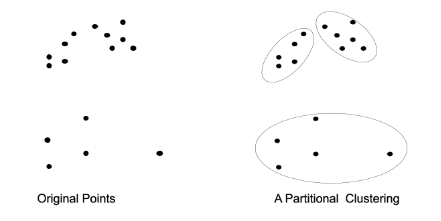

# Clustering for Online Retailers

## Dataset: The e-Retailer Customers

- Online Course Retailer:
    - Customer demographics
    - Course info (e.g., history, math, etc.) 
    - Customers’ channel preferences (email/mail contact)

- Use the **Clustering_Lab11.csv** file in the **lab_11** folder. Open **Clustering_Dictionary_Lab11.xlsx**, in the same folder, in Excel to understand each of the attributes.


## K-means clustering: Data Preparation

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Ignore useless warnings (see SciPy issue #5998)
import warnings
warnings.simplefilter("ignore", UserWarning)

from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

In [2]:
df = pd.read_csv('Clustering_Lab11.csv')
print(df.dtypes)
display(df.head())
df.describe()

CustomerID                     int64
IncomeDescription              int64
Education                      int64
NetWorth                       int64
Gender                        object
PresenceOfChildren             int64
BirthYear                      int64
FlagAudioVideo_order          object
FlagDigitalPhysical_order     object
numSubjectCategory_AH_all      int64
numSubjectCategory_EC_all      int64
numSubjectCategory_FW_all      int64
numSubjectCategory_HS_all      int64
numSubjectCategory_LIT_all     int64
numSubjectCategory_MH_all      int64
numSubjectCategory_MSC_all     int64
numSubjectCategory_MTH_all     int64
numSubjectCategory_PH_all      int64
numSubjectCategory_PR_all      int64
numSubjectCategory_RL_all      int64
numSubjectCategory_SCI_all     int64
numSubjectCategory_VA_all      int64
FlagEmail_latest               int64
FlagMailPref_latest            int64
dtype: object


,CustomerID,IncomeDescription,Education,NetWorth,Gender,PresenceOfChildren,BirthYear,FlagAudioVideo_order,FlagDigitalPhysical_order,numSubjectCategory_AH_all,...,numSubjectCategory_MH_all,numSubjectCategory_MSC_all,numSubjectCategory_MTH_all,numSubjectCategory_PH_all,numSubjectCategory_PR_all,numSubjectCategory_RL_all,numSubjectCategory_SCI_all,numSubjectCategory_VA_all,FlagEmail_latest,FlagMailPref_latest
0,50502779,7,4,9,Female,2,1942,Video Only,Physical Only,0,...,0,0,0,0,0,0,1,0,0,1
1,50566758,9,2,9,Male,2,1947,Both,Physical Only,0,...,0,0,0,0,0,2,0,0,1,1
2,50562027,3,3,1,Male,2,1954,Video Only,Physical Only,0,...,0,0,1,0,0,0,0,0,0,1
3,50655569,9,4,7,Male,2,1978,Video Only,Physical Only,0,...,0,0,0,0,1,0,0,0,1,1
4,50534230,9,2,6,Female,1,1930,Video Only,Physical Only,0,...,0,0,0,0,0,0,4,0,0,1


,CustomerID,IncomeDescription,Education,NetWorth,PresenceOfChildren,BirthYear,numSubjectCategory_AH_all,numSubjectCategory_EC_all,numSubjectCategory_FW_all,numSubjectCategory_HS_all,...,numSubjectCategory_MH_all,numSubjectCategory_MSC_all,numSubjectCategory_MTH_all,numSubjectCategory_PH_all,numSubjectCategory_PR_all,numSubjectCategory_RL_all,numSubjectCategory_SCI_all,numSubjectCategory_VA_all,FlagEmail_latest,FlagMailPref_latest
count,5.100000e+03,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,...,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000
mean,5.042320e+07,7.097647,3.305686,6.138627,1.739608,1951.098627,0.097059,0.133137,0.495686,0.064902,...,0.070588,0.089608,0.290392,0.056863,0.124118,0.265294,0.338431,0.078627,0.756078,0.996471
std,2.564929e+05,2.590711,0.888403,3.171041,0.438892,12.088299,0.383253,0.459499,0.827658,0.320423,...,0.303793,0.398086,0.656993,0.267736,0.411740,0.717918,0.720074,0.320408,0.429488,0.059310
min,5.000024e+07,1.000000,1.000000,1.000000,1.000000,1915.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.020725e+07,6.000000,3.000000,3.000000,1.000000,1944.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
50%,5.041846e+07,7.000000,4.000000,7.000000,2.000000,1951.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
75%,5.062499e+07,9.000000,4.000000,9.000000,2.000000,1957.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,5.093043e+07,13.000000,5.000000,10.000000,2.000000,1993.000000,11.000000,6.000000,9.000000,8.000000,...,3.000000,10.000000,6.000000,3.000000,4.000000,10.000000,10.000000,3.000000,1.000000,1.000000


### Convert categorical data to numerical (dummies) and drop ID

In [3]:
cate_col = ['Gender', 'PresenceOfChildren','IncomeDescription','Education','NetWorth',
            'FlagAudioVideo_order', 'FlagDigitalPhysical_order',
            'FlagEmail_latest','FlagMailPref_latest']
# Label missing values explicitly so they become their own dummy column.
# (pandas 2 turned them into the text 'nan'; pandas 3 keeps them missing and
# get_dummies would silently drop them - this line gives the same result in both.)
df[cate_col] = df[cate_col].fillna('Missing').astype('str')
df[cate_col].dtypes

Gender                       object
PresenceOfChildren           object
IncomeDescription            object
Education                    object
NetWorth                     object
FlagAudioVideo_order         object
FlagDigitalPhysical_order    object
FlagEmail_latest             object
FlagMailPref_latest          object
dtype: object

In [4]:
#Display the value counts
for i in cate_col:
    print(i)
    print(df[i].value_counts())
    print()

Gender
Gender
Male       2399
Female     1793
Unknown     908
Name: count, dtype: int64

PresenceOfChildren
PresenceOfChildren
2    3772
1    1328
Name: count, dtype: int64

IncomeDescription
IncomeDescription
7     1461
6      744
9      474
8      455
10     386
5      325
4      248
11     231
3      213
12     207
1      187
13      85
2       84
Name: count, dtype: int64

Education
Education
4    2356
3    1427
2    1041
5     199
1      77
Name: count, dtype: int64

NetWorth
NetWorth
1     1038
7      898
8      752
10     737
9      640
6      430
5      234
3      137
2      130
4      104
Name: count, dtype: int64

FlagAudioVideo_order
FlagAudioVideo_order
Video Only    4017
Audio Only     649
Both           426
Missing          8
Name: count, dtype: int64

FlagDigitalPhysical_order
FlagDigitalPhysical_order
Physical Only    4469
Digital Only      558
Both               65
Missing             8
Name: count, dtype: int64

FlagEmail_latest
FlagEmail_latest
1    3856
0    1244
Na

In [5]:
# Replace categorical variables with dummy variables, drop CustomerID
dummy_df = pd.get_dummies(df[cate_col])
customer = pd.concat([df.drop(cate_col, axis =1), dummy_df], axis = 1)
customer.drop('CustomerID', axis = 1, inplace = True)
print(customer.shape)
customer.columns

(5100, 59)


Index(['BirthYear', 'numSubjectCategory_AH_all', 'numSubjectCategory_EC_all',
       'numSubjectCategory_FW_all', 'numSubjectCategory_HS_all',
       'numSubjectCategory_LIT_all', 'numSubjectCategory_MH_all',
       'numSubjectCategory_MSC_all', 'numSubjectCategory_MTH_all',
       'numSubjectCategory_PH_all', 'numSubjectCategory_PR_all',
       'numSubjectCategory_RL_all', 'numSubjectCategory_SCI_all',
       'numSubjectCategory_VA_all', 'Gender_Female', 'Gender_Male',
       'Gender_Unknown', 'PresenceOfChildren_1', 'PresenceOfChildren_2',
       'IncomeDescription_1', 'IncomeDescription_10', 'IncomeDescription_11',
       'IncomeDescription_12', 'IncomeDescription_13', 'IncomeDescription_2',
       'IncomeDescription_3', 'IncomeDescription_4', 'IncomeDescription_5',
       'IncomeDescription_6', 'IncomeDescription_7', 'IncomeDescription_8',
       'IncomeDescription_9', 'Education_1', 'Education_2', 'Education_3',
       'Education_4', 'Education_5', 'NetWorth_1', 'NetWorth_10', 'Ne

In [6]:
customer.describe()

,BirthYear,numSubjectCategory_AH_all,numSubjectCategory_EC_all,numSubjectCategory_FW_all,numSubjectCategory_HS_all,numSubjectCategory_LIT_all,numSubjectCategory_MH_all,numSubjectCategory_MSC_all,numSubjectCategory_MTH_all,numSubjectCategory_PH_all,numSubjectCategory_PR_all,numSubjectCategory_RL_all,numSubjectCategory_SCI_all,numSubjectCategory_VA_all
count,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000
mean,1951.098627,0.097059,0.133137,0.495686,0.064902,0.161176,0.070588,0.089608,0.290392,0.056863,0.124118,0.265294,0.338431,0.078627
std,12.088299,0.383253,0.459499,0.827658,0.320423,0.518251,0.303793,0.398086,0.656993,0.267736,0.411740,0.717918,0.720074,0.320408
min,1915.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1944.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1951.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1957.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1993.000000,11.000000,6.000000,9.000000,8.000000,6.000000,3.000000,10.000000,6.000000,3.000000,4.000000,10.000000,10.000000,3.000000


### Transform all attributes to a range of [0,1]
Clustering algorithms are affected by feature scaling, because they rely on distances.

In [7]:
scaler = MinMaxScaler()
norm_customer = pd.DataFrame(data = scaler.fit_transform(customer), columns = customer.columns)
norm_customer.describe()

,BirthYear,numSubjectCategory_AH_all,numSubjectCategory_EC_all,numSubjectCategory_FW_all,numSubjectCategory_HS_all,numSubjectCategory_LIT_all,numSubjectCategory_MH_all,numSubjectCategory_MSC_all,numSubjectCategory_MTH_all,numSubjectCategory_PH_all,...,FlagAudioVideo_order_Missing,FlagAudioVideo_order_Video Only,FlagDigitalPhysical_order_Both,FlagDigitalPhysical_order_Digital Only,FlagDigitalPhysical_order_Missing,FlagDigitalPhysical_order_Physical Only,FlagEmail_latest_0,FlagEmail_latest_1,FlagMailPref_latest_0,FlagMailPref_latest_1
count,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,...,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000
mean,0.462803,0.008824,0.022190,0.055076,0.008113,0.026863,0.023529,0.008961,0.048399,0.018954,...,0.001569,0.787647,0.012745,0.109412,0.001569,0.876275,0.243922,0.756078,0.003529,0.996471
std,0.154978,0.034841,0.076583,0.091962,0.040053,0.086375,0.101264,0.039809,0.109499,0.089245,...,0.039579,0.409013,0.112183,0.312186,0.039579,0.329300,0.429488,0.429488,0.059310,0.059310
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.371795,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
50%,0.461538,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
75%,0.538462,0.000000,0.000000,0.111111,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Data Preparation Results
- ID attribute should not be used in distance calculation
- All the nominal attributes are properly converted to numerical attributes
- All the attributes have the same range [0,1]


## K-means clustering: Evaluation and Choose K


For detailed usage, check the documentation at [sklearn.cluster.KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)

### Use Sum of Squared Error to Choose the best K

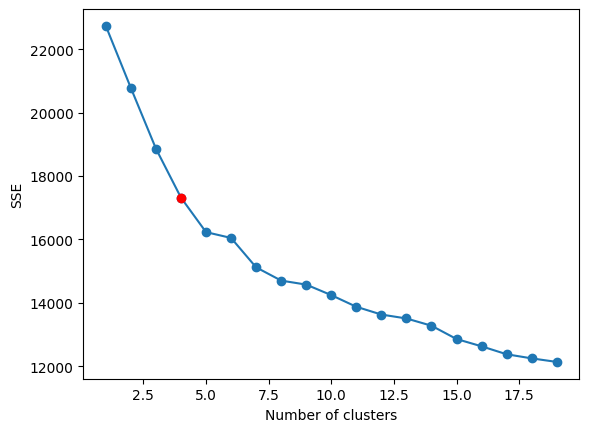

In [8]:
sse = [] # Sum of Squared Error of data points to centroid; The smaller the better.
for i in range(1, 20): # try 1 to 19 clusters
    customer_kmeans = KMeans(n_clusters = i, random_state = 42)
    customer_kmeans.fit(norm_customer)
    sse.append(customer_kmeans.inertia_)
    
plt.plot(range(1, 20), sse, marker = 'o')
plt.plot(4, sse[3], color = 'r', marker = 'o') # plot red mark on k = 4
plt.xlabel('Number of clusters')
plt.ylabel('SSE')
plt.show()

From the graph, 4 clusters is a relatively good choice for this dataset, since after this point the SSE decreases slowly (the elbow point).

## K-Means clustering: Compute Centroid Table

### Try K = 4

In [9]:
customer_kmeans_4 = KMeans(n_clusters = 4, random_state = 42)
customer_kmeans_4.fit(norm_customer)
#customer_kmeans_4.labels_

KMeans(n_clusters=4, random_state=42)

### Create centroid table

In [10]:
norm_customer['cluster'] = customer_kmeans_4.labels_
print(norm_customer['cluster'].value_counts())
norm_customer.describe()

cluster
0    2078
1    1217
2     917
3     888
Name: count, dtype: int64


,BirthYear,numSubjectCategory_AH_all,numSubjectCategory_EC_all,numSubjectCategory_FW_all,numSubjectCategory_HS_all,numSubjectCategory_LIT_all,numSubjectCategory_MH_all,numSubjectCategory_MSC_all,numSubjectCategory_MTH_all,numSubjectCategory_PH_all,...,FlagAudioVideo_order_Video Only,FlagDigitalPhysical_order_Both,FlagDigitalPhysical_order_Digital Only,FlagDigitalPhysical_order_Missing,FlagDigitalPhysical_order_Physical Only,FlagEmail_latest_0,FlagEmail_latest_1,FlagMailPref_latest_0,FlagMailPref_latest_1,cluster
count,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,...,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000
mean,0.462803,0.008824,0.022190,0.055076,0.008113,0.026863,0.023529,0.008961,0.048399,0.018954,...,0.787647,0.012745,0.109412,0.001569,0.876275,0.243922,0.756078,0.003529,0.996471,1.120588
std,0.154978,0.034841,0.076583,0.091962,0.040053,0.086375,0.101264,0.039809,0.109499,0.089245,...,0.409013,0.112183,0.312186,0.039579,0.329300,0.429488,0.429488,0.059310,0.059310,1.126691
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.371795,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
50%,0.461538,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000
75%,0.538462,0.000000,0.000000,0.111111,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,2.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000


### Restore the original value for continuous numerical variables

In [11]:
var_names = []
for col in customer.columns:
    if col == "BirthYear" or "numSubject" in col:
        var_names.append(col)
        norm_customer[col] = customer[col]
norm_customer[["BirthYear", "numSubjectCategory_AH_all"]].describe()

,BirthYear,numSubjectCategory_AH_all
count,5100.000000,5100.000000
mean,1951.098627,0.097059
std,12.088299,0.383253
min,1915.000000,0.000000
25%,1944.000000,0.000000
50%,1951.000000,0.000000
75%,1957.000000,0.000000
max,1993.000000,11.000000


In [12]:
pd.set_option('display.max_rows', 100)
group = norm_customer.groupby('cluster').mean().T
group

cluster,0,1,2,3
BirthYear,1947.290664,1961.135579,1946.502726,1951.000000
numSubjectCategory_AH_all,0.095765,0.086278,0.093784,0.118243
numSubjectCategory_EC_all,0.124158,0.156122,0.119956,0.136261
numSubjectCategory_FW_all,0.489413,0.479869,0.507088,0.520270
numSubjectCategory_HS_all,0.043311,0.123254,0.053435,0.047297
numSubjectCategory_LIT_all,0.155919,0.181594,0.183206,0.122748
numSubjectCategory_MH_all,0.064966,0.070666,0.073064,0.081081
numSubjectCategory_MSC_all,0.106352,0.069844,0.077426,0.090090
numSubjectCategory_MTH_all,0.263234,0.354150,0.292257,0.264640
numSubjectCategory_PH_all,0.047642,0.064092,0.052345,0.073198


<div style="background-color:#DFF5DC; color:#14532D; border:1px solid #A5D6A7; border-left:5px solid #2E7D32; padding:15px; margin-bottom:20px; border-radius:4px;">
    <b>Exercise: Build Persona </b><br>
Based on the centroid table, pick one cluster and build a persona and marketing strategy.
</div>

# Example Persona

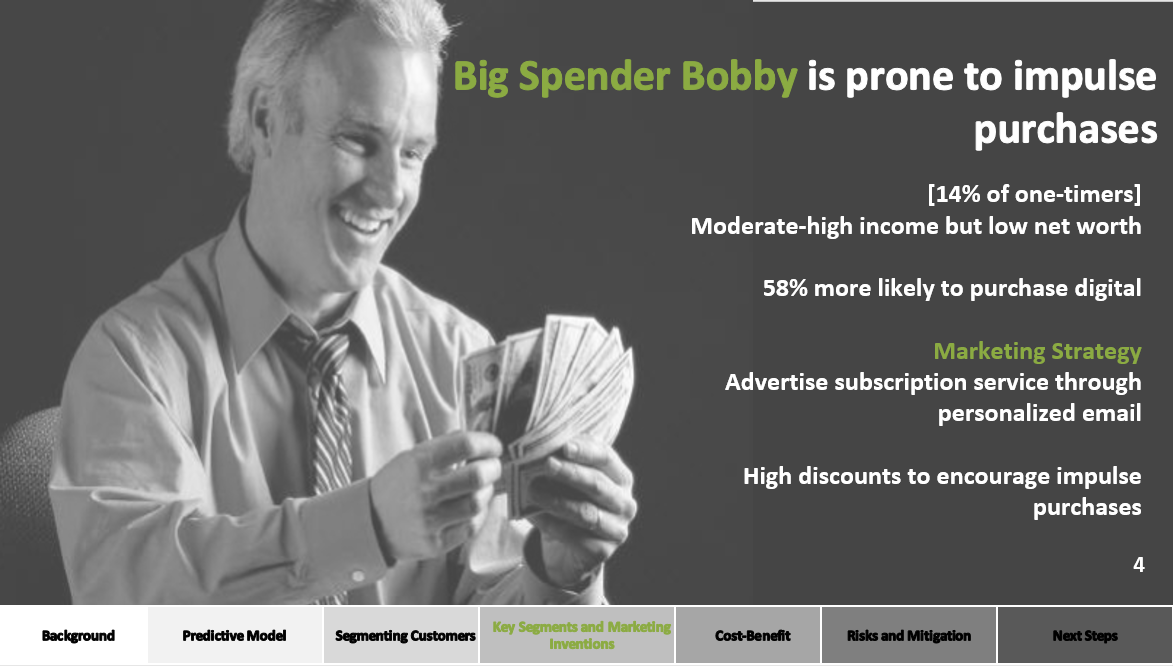
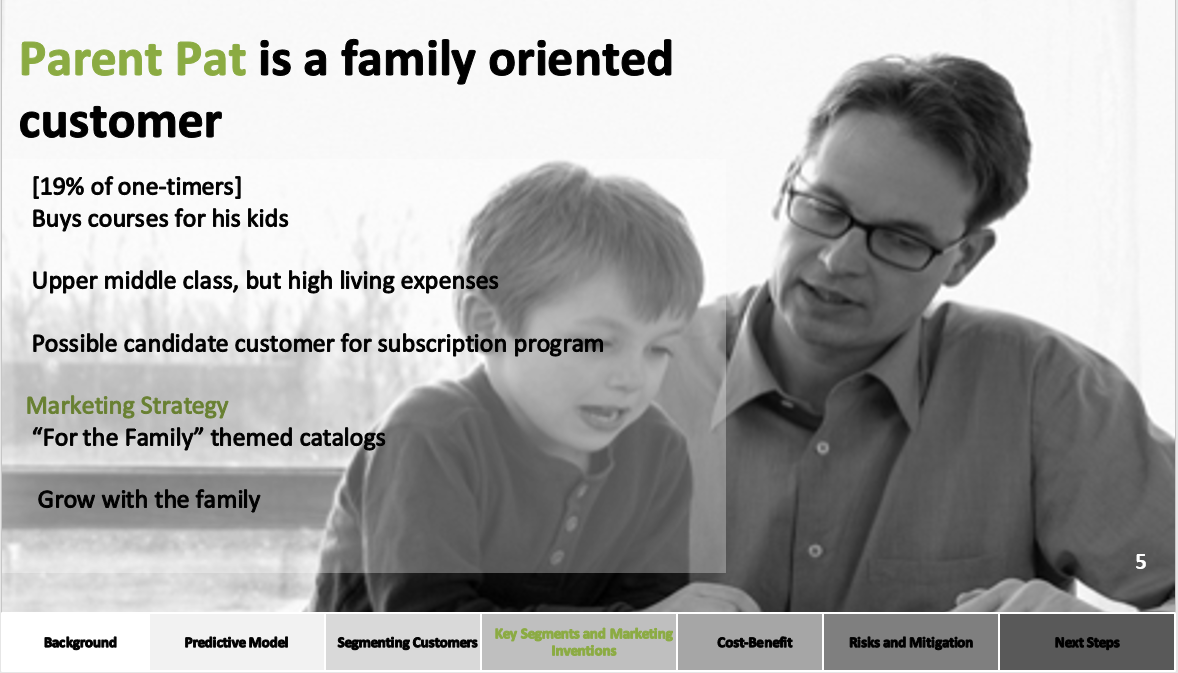
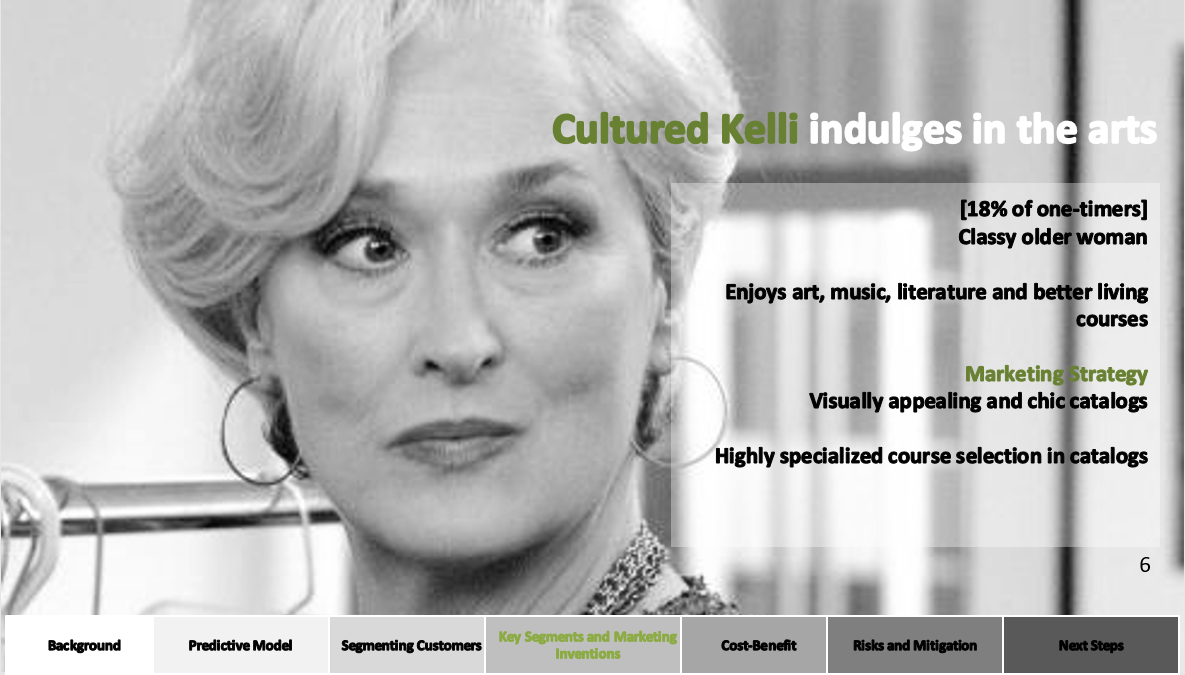

# Optional, after class. Claude Code: A Second Opinion from an Independent Agent
This part is optional; do it after class if you want to try it. Naming clusters is a judgment call, and an agent's answer depends on what is in its context. In this part, two agents name the same four clusters. **Agent A** has seen the lab notebook and your persona. **Agent B** starts fresh and gets only the data and the question. You compare the two and decide with the numbers.

This is the same idea as an ensemble in Lab 10: a second model helps only if it can make different errors. Two answers from one conversation are not independent, because the second one has read the first.

**Finish the persona exercise above first.**

## Step 1: Save the Centroid Table
Run the cell below. It saves the centroid table and the cluster sizes in the `lab_11` folder, so that both agents read the same numbers.

In [13]:
group.to_csv("lab_11_centroids_k4.csv")
norm_customer["cluster"].value_counts().sort_index().to_csv("lab_11_cluster_sizes.csv")
print(norm_customer["cluster"].value_counts().sort_index())

cluster
0    2078
1    1217
2     917
3     888
Name: count, dtype: int64


## Step 2: Agent A (shared context)
Start `claude` in `comm4259-work` and paste this prompt, with your persona from the exercise:

```
Read lab_11/Lab_11-Clustering.ipynb, lab_11/lab_11_centroids_k4.csv and lab_11/lab_11_cluster_sizes.csv.
lab_11/Clustering_Dictionary_Lab11.xlsx explains the columns.
Here is my persona for one of the clusters: <paste your persona here>
Give each of the four clusters a short name and a two-sentence description for a marketing manager. Do not change any files.
```

Copy Agent A's names into the table in Step 4. Leave this terminal open.

## Step 3: Agent B (fresh context)
Open a **second terminal** in VS Code (the **+** in the terminal panel). From `comm4259-work`, start `claude` and paste this prompt. It has the same data and the same question, but not the notebook and not your persona:

```
Read lab_11/lab_11_centroids_k4.csv and lab_11/lab_11_cluster_sizes.csv. They describe four customer clusters of an online course retailer, from K-means. The values are cluster means: most columns are scaled to 0-1, while BirthYear and the numSubject columns are in their original units.
lab_11/Clustering_Dictionary_Lab11.xlsx explains the columns.
Give each of the four clusters a short name and a two-sentence description for a marketing manager. Do not change any files.
```

Another way to get a fresh agent is to ask Agent A to hand the question to a **subagent**, which starts with an empty context. A new session is easier to check, because you can see exactly what it was given.

## Step 4: Compare and Decide (no AI)
For each cluster, write both names, whether they agree, and two numbers from the centroid table that support the name you choose.

| Cluster | Size | Agent A's name | Agent B's name | Agree? | Your choice, and two supporting numbers |
|---|---|---|---|---|---|
| 0 | | | | | |
| 1 | | | | | |
| 2 | | | | | |
| 3 | | | | | |

Answer these questions:
1. Did Agent A repeat ideas from your persona? Give an example.
2. Where the agents disagree, which one do the numbers support?
3. Would a third agent, asked in Agent A's conversation, count as an independent opinion? Why or why not?

Your answers:
1.
2.
3.

Type `/exit` in both terminals when you are done.

# Before Class Ends
Save this notebook (Cmd+S or Ctrl+S). Then, from `comm4259-work`, commit and push your work:

```
git add .
git commit -m "Lab 11: clustering and personas"
git push
```